Integrantes da equipe: Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import pickle

# 1 - Importação dos dados Pré-Processados

In [2]:
with open('risco_credito.pkl', 'rb') as f:
    X_risco_credito, y_risco_credito = pickle.load(f)

# 2 - Algoritmo de Árvore de Decisão

## a) importar da biblioteca sklearn o pacote DecisionTreeClassifier

In [3]:
from sklearn.tree import DecisionTreeClassifier

## b) Calcule a árvore de decisão, utilizando como critério a entropia. Coloque como nome da variável: arvore_risco_credito

In [4]:
arvore_risco_credito = DecisionTreeClassifier(criterion='entropy')
arvore_risco_credito.fit(X_risco_credito, y_risco_credito)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the cu

## c) Utilize o feature_importances_ para retornar a importância de cada atributo. Qual possui o maior ganho de informação?

In [5]:
importances = arvore_risco_credito.feature_importances_
previsores = ['história', 'dívida', 'garantias', 'renda']
for i in range(len(previsores)):
    print(f'{previsores[i]}: {importances[i]:.4f}')

maior_ganho = previsores[np.argmax(importances)]
print(f'\nO atributo com maior ganho de informação é: {maior_ganho}')

história: 0.4161
dívida: 0.0641
garantias: 0.0389
renda: 0.4810

O atributo com maior ganho de informação é: renda


## d) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn. OBS: Adicione cores, nomes para os atributos e para as classes.

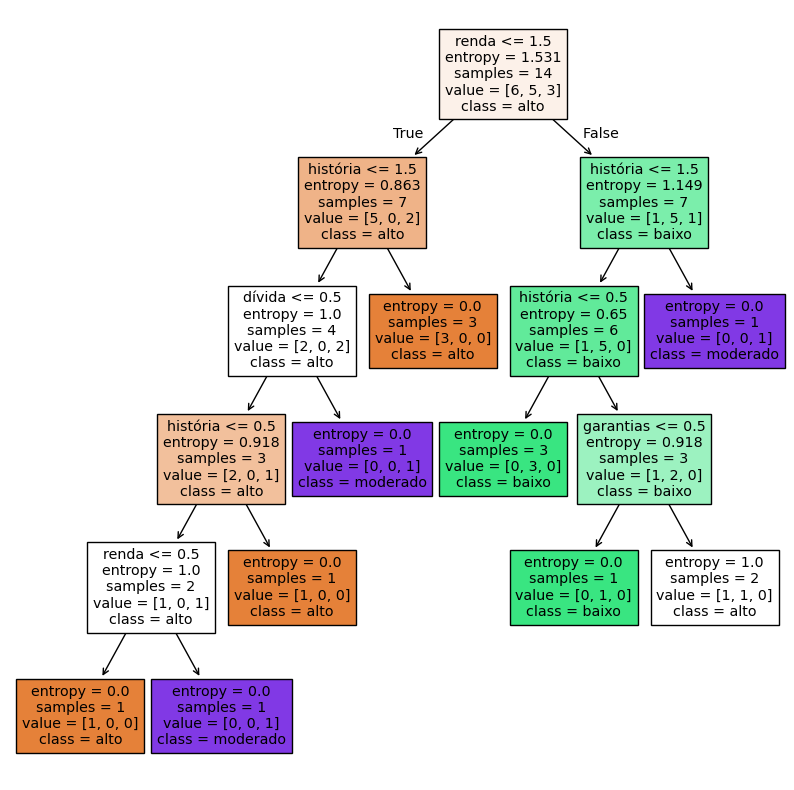

In [6]:
from sklearn import tree
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(10,10))
tree.plot_tree(arvore_risco_credito, feature_names=previsores, class_names=arvore_risco_credito.classes_, filled=True)
plt.show()

## e) FAZER A PREVISÃO

i. história boa, dívida alta, garantia nenhuma, renda > 35

ii. história ruim, dívida alta, garantia adequada, renda < 15

In [7]:
previsoes = arvore_risco_credito.predict([[0, 0, 1, 2], [2, 0, 0, 0]])
print(f'Previsão Cenário i: {previsoes[0]}')
print(f'Previsão Cenário ii: {previsoes[1]}')

Previsão Cenário i: baixo
Previsão Cenário ii: alto


# 3 - Algoritmo de Árvore de Decisão para uma base de dados maior (Credit Data)

Nesta seção testamos a Árvore de Decisão na base **Credit Risk Dataset**, analisando clientes que pagam (classe 0) ou não pagam (classe 1) a dívida.

In [8]:
from sklearn.tree import plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

with open('credit.pkl', 'rb') as f:
    X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

## a) Verificar o tamanho dos dados

Os dados de treinamento devem ter: x=(1500, 3), y=(1500,); os dados de teste: x=(500, 3), y=(500,).

In [9]:
print('--- Dimensões dos dados (Credit Data) ---')
print(f'X treinamento : {X_credit_treinamento.shape}')
print(f'y treinamento : {y_credit_treinamento.shape}')
print(f'X teste       : {X_credit_teste.shape}')
print(f'y teste       : {y_credit_teste.shape}')

--- Dimensões dos dados (Credit Data) ---
X treinamento : (1500, 3)
y treinamento : (1500,)
X teste       : (500, 3)
y teste       : (500,)


## b) Treinar o modelo de Árvore de Decisão

`random_state=0` garante reprodutibilidade dos resultados.

In [10]:
arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_credit_treinamento, y_credit_treinamento)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

## c) Previsão com os dados de teste

Comparação entre previsões e valores reais.

In [11]:
previsoes_credit = arvore_credit.predict(X_credit_teste)

comparacao = pd.DataFrame({
    'Previsão' : previsoes_credit[:20],
    'Real'     : y_credit_teste[:20]
})
print('--- Comparação previsões x valores reais (primeiros 20) ---')
print(comparacao.to_string(index=False))

--- Comparação previsões x valores reais (primeiros 20) ---
 Previsão  Real
        1     1
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        0     0
        1     1
        0     0
        0     0
        1     1


## d) Cálculo da acurácia

In [12]:
from sklearn.metrics import accuracy_score, classification_report

acuracia_credit = accuracy_score(y_credit_teste, previsoes_credit)
print(f'Acurácia do modelo (Credit Data): {acuracia_credit:.4f} ({acuracia_credit*100:.2f}%)')

print()
print('Relatorio de Classificacao:')
print(classification_report(
    y_credit_teste,
    previsoes_credit,
    target_names=['Paga (0)', 'Não paga (1)']
))

Acurácia do modelo (Credit Data): 0.9820 (98.20%)

Relatorio de Classificacao:
              precision    recall  f1-score   support

    Paga (0)       0.99      0.99      0.99       436
Não paga (1)       0.91      0.95      0.93        64

    accuracy                           0.98       500
   macro avg       0.95      0.97      0.96       500
weighted avg       0.98      0.98      0.98       500



## e) Análise da Matriz de Confusão

- i. Quantos clientes foram classificados corretamente como pagantes?
- ii. Quantos clientes foram classificados incorretamente como não pagantes?
- iii. Quantos clientes foram classificados corretamente como não pagantes?
- iv. Quantos clientes foram classificados incorretamente como pagantes?

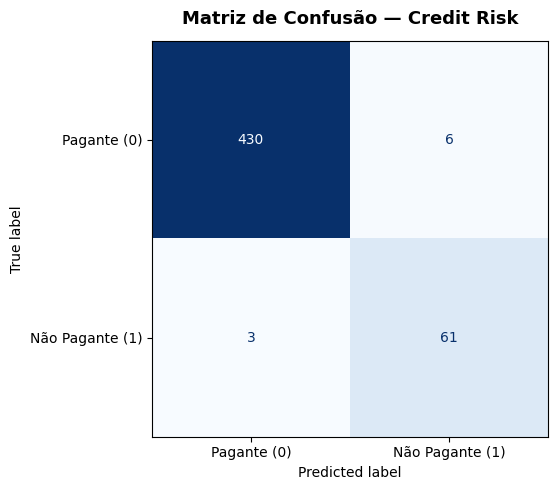

i.   Pagantes classificados CORRETAMENTE (VP):              430
  ii.  Pagantes classificados como NÃO PAGANTES - erro (FP): 6
  iii. Não pagantes classificados CORRETAMENTE (VN):          61
  iv.  Não pagantes classificados como PAGANTES - erro (FN):  3


In [13]:
mat = confusion_matrix(y_credit_teste, previsoes_credit)
vp = mat[0][0]   # Pagantes classificados corretamente
fp = mat[0][1]   # Pagantes classificados como não pagantes (erro)
fn = mat[1][0]   # Não pagantes classificados como pagantes (erro)
vn = mat[1][1]   # Não pagantes classificados corretamente

fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=mat,
    display_labels=['Pagante (0)', 'Não Pagante (1)']
)
disp.plot(cmap='Blues', ax=ax_cm, colorbar=False)
ax_cm.set_title('Matriz de Confusão — Credit Risk', fontsize=13, fontweight='bold', pad=12)
fig_cm.tight_layout()
fig_cm.savefig('matriz_confusao.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'i.   Pagantes classificados CORRETAMENTE (VP):              {vp}')
print(f'  ii.  Pagantes classificados como NÃO PAGANTES - erro (FP): {fp}')
print(f'  iii. Não pagantes classificados CORRETAMENTE (VN):          {vn}')
print(f'  iv.  Não pagantes classificados como PAGANTES - erro (FN):  {fn}')

## f) Classification Report

Explique a relação entre precision e recall. Como você interpreta esses dados?

In [14]:
print(classification_report(
    y_credit_teste,
    previsoes_credit,
    target_names=['Pagante (0)', 'Não Pagante (1)']
))

print("""
INTERPRETAÇÃO — Precision vs Recall:

  • Precision (Precisão): dos clientes que o modelo marcou
    como pertencentes a uma classe, quantos realmente são?
    → 'Quando o modelo alerta não vai pagar, quão confiável é esse alerta?'

  • Recall (Sensibilidade): de todos os clientes que
    realmente pertencem a uma classe, quantos o modelo detectou?
    → 'De todos os inadimplentes reais, quantos o modelo conseguiu identificar?'

  CLASSE 0 — Pagante:
    Precision ~0.99 e Recall ~0.99 → o modelo é excelente em identificar
    bons pagadores. Esperado, pois esta classe é maioria nos dados.

  CLASSE 1 — Não Pagante:
    Precision ~0.91 e Recall ~0.94 → de 64 inadimplentes reais, o modelo
    detectou ~94% (apenas 4 escaparam). Dos alertas emitidos, 91% eram
    inadimplentes de fato.

  TRADE-OFF no contexto bancário:
    Recall da classe 1 é a métrica mais crítica: um inadimplente não
    detectado (falso negativo) representa um empréstimo concedido a quem
    não pagará — prejuízo direto. Recall de 94% é satisfatório.
""")

                 precision    recall  f1-score   support

    Pagante (0)       0.99      0.99      0.99       436
Não Pagante (1)       0.91      0.95      0.93        64

       accuracy                           0.98       500
      macro avg       0.95      0.97      0.96       500
   weighted avg       0.98      0.98      0.98       500


INTERPRETAÇÃO — Precision vs Recall:

  • Precision (Precisão): dos clientes que o modelo marcou
    como pertencentes a uma classe, quantos realmente são?
    → 'Quando o modelo alerta não vai pagar, quão confiável é esse alerta?'

  • Recall (Sensibilidade): de todos os clientes que
    realmente pertencem a uma classe, quantos o modelo detectou?
    → 'De todos os inadimplentes reais, quantos o modelo conseguiu identificar?'

  CLASSE 0 — Pagante:
    Precision ~0.99 e Recall ~0.99 → o modelo é excelente em identificar
    bons pagadores. Esperado, pois esta classe é maioria nos dados.

  CLASSE 1 — Não Pagante:
    Precision ~0.91 e Recall ~0

## g) Visualização da Árvore de Decisão

Atributos previsores: `['income', 'age', 'loan']`

Árvore salva em: arvore_credit.png


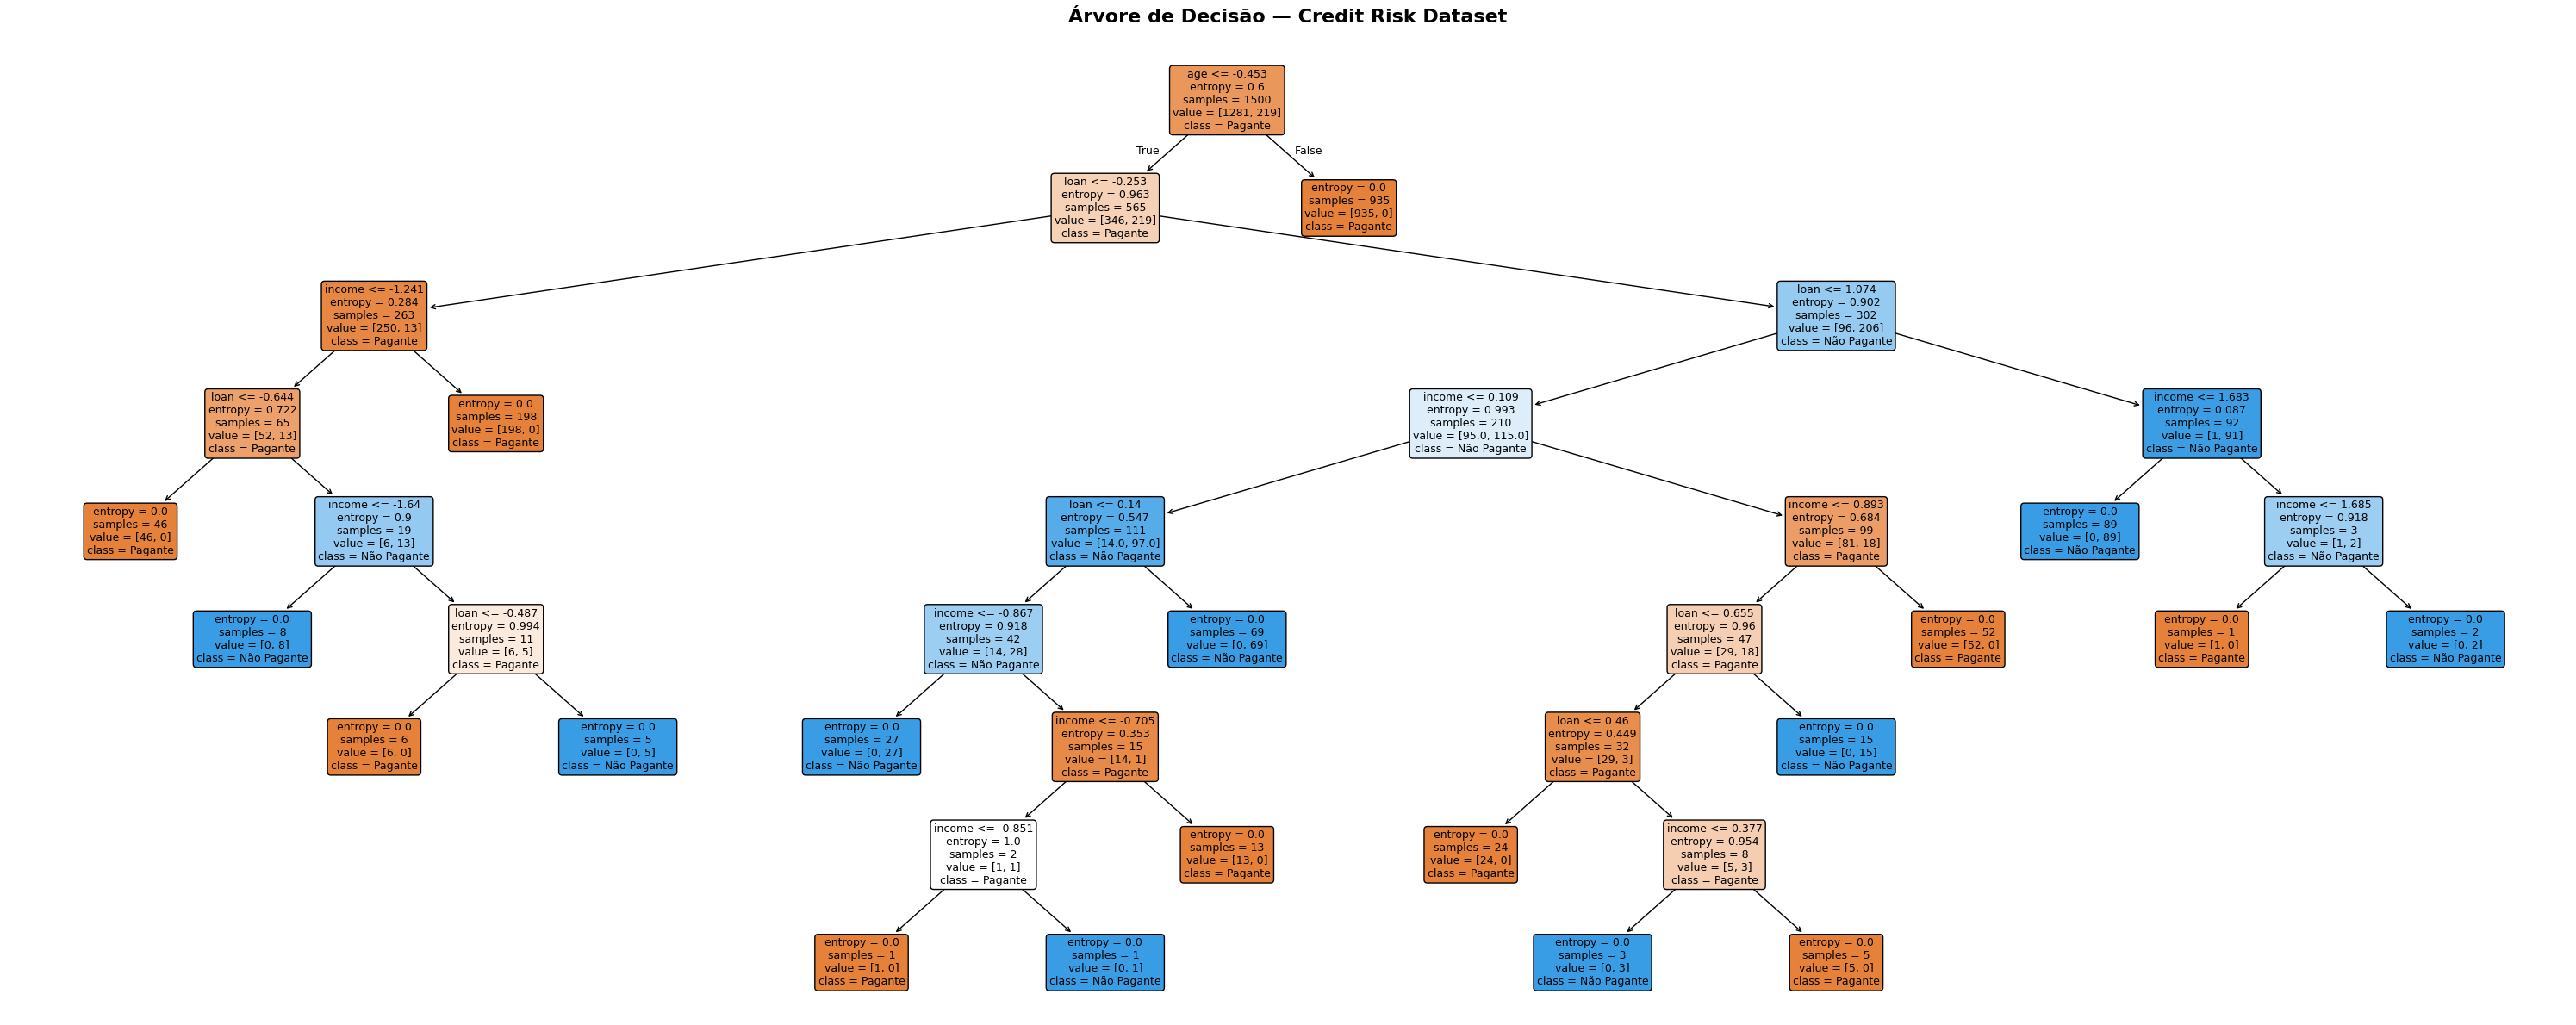

In [15]:
fig_tree, ax_tree = plt.subplots(figsize=(30, 12))

plot_tree(
    arvore_credit,
    feature_names=['income', 'age', 'loan'],
    class_names=['Pagante', 'Não Pagante'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax_tree
)

ax_tree.set_title(
    'Árvore de Decisão — Credit Risk Dataset',
    fontsize=16, fontweight='bold', pad=20
)

fig_tree.tight_layout()
fig_tree.savefig('arvore_credit.png', dpi=150, bbox_inches='tight')
print('Árvore salva em: arvore_credit.png')
plt.show()

# Algoritmo Random Forest

Nesta seção iremos utilizar o algoritmo Random Forest para a mesma base de crédito (**Credit Risk Dataset**) — arquivo *credit.pkl*.

## a) Importar RandomForestClassifier do sklearn

In [16]:
from sklearn.ensemble import RandomForestClassifier

## b) Treinar o Random Forest

Parâmetros:
- `n_estimators=10` → número de árvores criadas
- `criterion='entropy'`
- `random_state=0`

In [17]:
random_forest_credit = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
random_forest_credit.fit(X_credit_treinamento, y_credit_treinamento)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metr

## c) Previsão com dados de teste

In [18]:
previsoes_rf = random_forest_credit.predict(X_credit_teste)
print('Primeiras 10 previsões RF:', previsoes_rf[:10])
print('Primeiros 10 valores reais:', y_credit_teste[:10])

Primeiras 10 previsões RF: [1 0 0 0 0 0 0 0 0 0]
Primeiros 10 valores reais: [1 0 0 0 0 0 0 0 0 0]


## d) Calcular acurácia — resultado melhor do que a árvore de decisão simples?

In [19]:
acuracia_rf = accuracy_score(y_credit_teste, previsoes_rf)
print(f'Acurácia Random Forest (10 árvores): {acuracia_rf:.4f} ({acuracia_rf*100:.2f}%)')
print(f'Acurácia Árvore de Decisão:           {acuracia_credit:.4f} ({acuracia_credit*100:.2f}%)')
if acuracia_rf > acuracia_credit:
    print('O Random Forest obteve resultado MELHOR que a árvore simples.')
else:
    print('O Random Forest obteve resultado IGUAL ou INFERIOR à árvore simples.')

Acurácia Random Forest (10 árvores): 0.9680 (96.80%)
Acurácia Árvore de Decisão:           0.9820 (98.20%)
O Random Forest obteve resultado IGUAL ou INFERIOR à árvore simples.


## e) Se o resultado foi inferior, como resolver?

Caso o Random Forest com 10 árvores tenha desempenho inferior ou igual, aumentamos `n_estimators` e testamos o impacto na acurácia.

In [20]:
resultados = {}
for n in [10, 40, 100, 200]:
    rf_tmp = RandomForestClassifier(n_estimators=n, criterion='entropy', random_state=0)
    rf_tmp.fit(X_credit_treinamento, y_credit_treinamento)
    prev_tmp = rf_tmp.predict(X_credit_teste)
    acc = accuracy_score(y_credit_teste, prev_tmp)
    resultados[n] = acc
    print(f'n_estimators={n:3d}: acurácia = {acc:.4f} ({acc*100:.2f}%)')

melhor_n = max(resultados, key=resultados.get)
print(f'Melhor resultado: n_estimators={melhor_n} com acurácia {resultados[melhor_n]:.4f}')

n_estimators= 10: acurácia = 0.9680 (96.80%)
n_estimators= 40: acurácia = 0.9840 (98.40%)
n_estimators=100: acurácia = 0.9820 (98.20%)
n_estimators=200: acurácia = 0.9820 (98.20%)
Melhor resultado: n_estimators=40 com acurácia 0.9840


## f) Análise da Matriz de Confusão

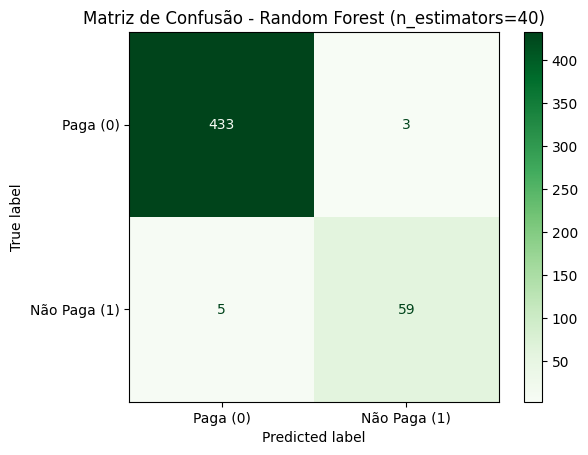

i.  Classificados corretamente como pagantes (TN):          433
ii. Classificados incorretamente como não pagantes (FN):    5
iii.Classificados corretamente como não pagantes (TP):      59
iv. Classificados incorretamente como pagantes (FP):        3


In [21]:
rf_40 = RandomForestClassifier(n_estimators=40, criterion='entropy', random_state=0)
rf_40.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_rf_40 = rf_40.predict(X_credit_teste)

cm_rf_matrix = confusion_matrix(y_credit_teste, previsoes_rf_40)
cm_rf_display = ConfusionMatrixDisplay(confusion_matrix=cm_rf_matrix, display_labels=['Paga (0)', 'Não Paga (1)'])
cm_rf_display.plot(cmap='Greens')
plt.title('Matriz de Confusão - Random Forest (n_estimators=40)')
plt.savefig('matriz_confusao_rf.png', dpi=150, bbox_inches='tight')
plt.show()

tn_rf, fp_rf, fn_rf, tp_rf = cm_rf_matrix.ravel()
print(f'i.  Classificados corretamente como pagantes (TN):          {tn_rf}')
print(f'ii. Classificados incorretamente como não pagantes (FN):    {fn_rf}')
print(f'iii.Classificados corretamente como não pagantes (TP):      {tp_rf}')
print(f'iv. Classificados incorretamente como pagantes (FP):        {fp_rf}')

## g) classification_report e relação Precision × Recall

Explique a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [ ]:
print(classification_report(y_credit_teste, previsoes_rf_40, target_names=["Paga (0)", "Nao Paga (1)"]))

              precision    recall  f1-score   support

    Paga (0)       0.99      0.99      0.99       436
Nao Paga (1)       0.95      0.92      0.94        64

    accuracy                           0.98       500
   macro avg       0.97      0.96      0.96       500
weighted avg       0.98      0.98      0.98       500



### Interpretação (Random Forest):

- O **Random Forest** combina múltiplas árvores de decisão, cada uma treinada com amostragem bootstrap e subconjunto aleatório de atributos. A classe final é decidida por **votação majoritária**.

- **Precision vs Recall**:
  - **Classe 0 (pagantes)**: Alta precision e recall são esperados, pois é a classe majoritária — o modelo tem mais exemplos para aprender.
  - **Classe 1 (inadimplentes)**: Se o recall é baixo, o modelo deixa passar inadimplentes (alto custo para o banco). Aumentar `n_estimators` e balancear as classes pode melhorar esse resultado.

- O Random Forest é mais robusto que a árvore simples pois reduz o **overfitting** ao agregar múltiplas árvores com diversidade introduzida pela amostragem aleatória.